In [1]:
import pandas as pd
import numpy as np
import os
import re
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)

sns.set_theme()

In [2]:
excel_path = r"C:\Users\minsa_\Downloads\Combined_Research_Dataset_Final.xlsx"

df_original = pd.read_excel(
    excel_path,
    sheet_name="Combined_Dataset"
)

# Create a working copy
df = df_original.copy(deep=True)

print("Dataset loaded successfully")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully
Rows: 1054
Columns: 85


In [3]:
print("Dataset shape:", df.shape)
print("\nColumn names:")

for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

Dataset shape: (1054, 85)

Column names:
1. Tissue_ID
2. Eye
3. Image_ID
4. Disease_Label
5. Disease_Severity
6. ECD_CD_cells_per_mm2
7. CV
8. HEX_percent
9. SD
10. Total_Cell_Count
11. Total_Area_um2
12. Epithelium_Findings
13. Epithelium_Severity
14. Stroma_Findings
15. Stroma_Severity
16. Descemet_Findings
17. Descemet_Severity
18. Endothelium_Findings
19. Endothelium_Severity
20. Additional_Findings
21. Tissue_Grade
22. Overall_Donor_Quality
23. Transplant_Suitability
24. Suitability_Reason
25. Primary_COD
26. Donor_Age
27. Tissue_Serial
28. Linkage_Status
29. Source_PDF
30. PDF_Pages
31. Konan_Report_File
32. SP_Image_File
33. Cell_Image_File
34. Konan_Raw_CorneaID
35. Konan_Exam_Date
36. Konan_Mean_Cell_Area_um2
37. Konan_Comments
38. Donor_Sex
39. Admitting_Diagnosis
40. Death_Date_Time
41. Preservation_Date_Time
42. Death_to_Preservation_Time
43. Storage_Medium
44. Serology_HBsAg
45. Serology_HCV
46. Serology_HIV
47. Serology_VDRL
48. Lens_Status
49. Form_ECD_cells_per_mm2
50. 

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1054 entries, 0 to 1053
Data columns (total 85 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Tissue_ID                   1054 non-null   str    
 1   Eye                         1054 non-null   str    
 2   Image_ID                    1045 non-null   str    
 3   Disease_Label               1054 non-null   str    
 4   Disease_Severity            545 non-null    str    
 5   ECD_CD_cells_per_mm2        1003 non-null   float64
 6   CV                          1003 non-null   float64
 7   HEX_percent                 1003 non-null   float64
 8   SD                          1002 non-null   float64
 9   Total_Cell_Count            956 non-null    float64
 10  Total_Area_um2              956 non-null    float64
 11  Epithelium_Findings         587 non-null    str    
 12  Epithelium_Severity         314 non-null    str    
 13  Stroma_Findings             588 non-null    

In [5]:
display(df.head(10))

,Tissue_ID,Eye,Image_ID,Disease_Label,Disease_Severity,ECD_CD_cells_per_mm2,CV,HEX_percent,SD,Total_Cell_Count,Total_Area_um2,Epithelium_Findings,Epithelium_Severity,Stroma_Findings,Stroma_Severity,Descemet_Findings,Descemet_Severity,Endothelium_Findings,Endothelium_Severity,Additional_Findings,Tissue_Grade,Overall_Donor_Quality,Transplant_Suitability,Suitability_Reason,Primary_COD,Donor_Age,Tissue_Serial,Linkage_Status,Source_PDF,PDF_Pages,Konan_Report_File,SP_Image_File,Cell_Image_File,Konan_Raw_CorneaID,Konan_Exam_Date,Konan_Mean_Cell_Area_um2,Konan_Comments,Donor_Sex,Admitting_Diagnosis,Death_Date_Time,Preservation_Date_Time,Death_to_Preservation_Time,Storage_Medium,Serology_HBsAg,Serology_HCV,Serology_HIV,Serology_VDRL,Lens_Status,Form_ECD_cells_per_mm2,Intended_Use,Tissue_Outcome,Recipient_Age,Recipient_Eye,Recipient_Indication,Request_Indication,Previous_Grafts,Primary_Procedure,Secondary_Procedures,Surgery_Date,Donor_Graft_Size_mm,Recipient_Bed_Size_mm,Suture_Technique,Intraop_Complications,Death_to_Surgery_Days,Request_Reg_No,Request_Issue_No,Request_Date,Proposed_Op_Date,Request_Urgency,Request_Indication_Type,Recipient_Sex,VA_Operative_Eye,VA_Fellow_Eye,Requested_Grade,Planned_Procedure,Requesting_Surgeon,Requesting_Hospital,Request_to_Surgery_Days,Grade_Request_Met,Dataset_Part,Tissue_Grade_Source,Disease_Label_Source,Needs_Review,Review_Notes,Merge_Filled_Columns
0,NEB-2020-09-12654 R,Right,NEB-2020-09-12654 R_SP,Normal,NaN,2132.0,33.0,58.0,153.0,24.0,11266.0,Clear and intact,NaN,Clear; arcus,Mild,Folds,Mild,NaN,NaN,Rim 3.5; cornea diameter 11 mm; corneoscleral 18 mm,B,NaN,NaN,NaN,Disseminated carcinoma of oesophagus,57.0,12654,Linked: form + Konan + image,12654R.pdf,6.0,NEB-2020-09-12654 RT.txt,NEB-2020-09-12654 R_SP.jpg,NEB-2020-09-12654 R_C.jpg,NEB-2020-09-12654 R,2020-09-14 0:00:00,469.0,T.H.KU/GALA-WD.50-ONCOLOGY,Male,Carcinoma of oesophagus,2020-09-13 12:20:00,2020-09-13 14:50:00,2 h 30 min,Eusol-C,Negative,Negative,Negative,Negative,NaN,2132,NaN,NaN,NaN,Right,NaN,Therapeutic,NaN,Lamellar keratoplasty (DALK),NaN,2020-09-18 0:00:00,8.25,8,Interrupted,NaN,5.0,NaN,NaN,NaN,NaN,NaN,Therapeutic,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Graded set (eye-bank forms),Eye-bank form,Eye-bank form,NaN,NaN,NaN
1,NEB-2020-09-12655 L,Left,NEB-2020-09-12655 L_SP,Folds,Moderate,2212.0,33.0,47.0,147.0,70.0,31637.0,"Exposure; peripheral (""mild exposure"")",Mild,Arcus,NaN,NaN,NaN,NaN,NaN,Rim 3.5; cornea diameter 11 mm; corneoscleral 18 mm,B,NaN,NaN,NaN,Disseminated carcinoma of oesophagus,57.0,12655,Linked: form + Konan + image,12655L.pdf,5.0,NEB-2020-09-12655 LT.txt,NEB-2020-09-12655 L_SP.jpg,NEB-2020-09-12655 L_C.jpg,NEB-2020-09-12655 L,2020-09-14 0:00:00,452.0,T.H.KU/GALA-WD.50-ONCOLOGY,Male,Carcinoma of oesophagus,NaN,NaN,2 h 30 min,NaN,NaN,NaN,NaN,NaN,NaN,2212,NaN,Cornea expired 27-09-2020 (handwritten note),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Graded set (eye-bank forms),Eye-bank form,Eye-bank form,NaN,NaN,NaN
2,NEB-2020-09-12656 R,Right,NEB-2020-09-12656 R_SP,Normal,NaN,2538.0,35.0,53.0,137.0,136.0,53575.0,Clear and intact,NaN,Clear; arcus,Mild,Folds,Mild,Stress lines; central; few,NaN,Rim 1.5-2; cornea diameter 11 mm; corneoscleral 17 mm; clear area 8 mm,A,Excellent,Suitable,NaN,Basilar artery thrombosis + cerebral infarction,51.0,12656,Linked: form + Konan + image,12656R.pdf,4.0,NEB-2020-09-12656 RT.txt,NEB-2020-09-12656 R_SP.jpg,NEB-2020-09-12656 R_C.jpg,NEB-2020-09-12656 R,2020-09-14 0:00:00,394.0,T.H.KU/GALA-WD.40-NEUROLOGY,Female,HT + polyarthritis (as read),2020-09-13 18:15:00,2020-09-13 20:30:00,2 h 15 min,Eusol-C,Negative,Negative,Negative,Negative,Phakic,2538,PKP - MK unit NEH 15/09/2020,NaN,NaN,Left (request form),L/E trauma / decompensated graft (as read),Optical,1,"PK (planned, request form)",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Optical,NaN,NaN,NaN,NaN,PK,NaN,NaN,NaN,NaN,Graded set (eye-bank forms),Eye-bank form,Eye-bank form,NaN

In [6]:
display(df.sample(min(10, len(df)), random_state=42))

,Tissue_ID,Eye,Image_ID,Disease_Label,Disease_Severity,ECD_CD_cells_per_mm2,CV,HEX_percent,SD,Total_Cell_Count,Total_Area_um2,Epithelium_Findings,Epithelium_Severity,Stroma_Findings,Stroma_Severity,Descemet_Findings,Descemet_Severity,Endothelium_Findings,Endothelium_Severity,Additional_Findings,Tissue_Grade,Overall_Donor_Quality,Transplant_Suitability,Suitability_Reason,Primary_COD,Donor_Age,Tissue_Serial,Linkage_Status,Source_PDF,PDF_Pages,Konan_Report_File,SP_Image_File,Cell_Image_File,Konan_Raw_CorneaID,Konan_Exam_Date,Konan_Mean_Cell_Area_um2,Konan_Comments,Donor_Sex,Admitting_Diagnosis,Death_Date_Time,Preservation_Date_Time,Death_to_Preservation_Time,Storage_Medium,Serology_HBsAg,Serology_HCV,Serology_HIV,Serology_VDRL,Lens_Status,Form_ECD_cells_per_mm2,Intended_Use,Tissue_Outcome,Recipient_Age,Recipient_Eye,Recipient_Indication,Request_Indication,Previous_Grafts,Primary_Procedure,Secondary_Procedures,Surgery_Date,Donor_Graft_Size_mm,Recipient_Bed_Size_mm,Suture_Technique,Intraop_Complications,Death_to_Surgery_Days,Request_Reg_No,Request_Issue_No,Request_Date,Proposed_Op_Date,Request_Urgency,Request_Indication_Type,Recipient_Sex,VA_Operative_Eye,VA_Fellow_Eye,Requested_Grade,Planned_Procedure,Requesting_Surgeon,Requesting_Hospital,Request_to_Surgery_Days,Grade_Request_Met,Dataset_Part,Tissue_Grade_Source,Disease_Label_Source,Needs_Review,Review_Notes,Merge_Filled_Columns
260,NEB-2024-05-16091 R,Right,NEB-2024-05-16091 R_SP,FECD; Polymorphism and pleomorphism; Low cell density,Mild,1704.0,27.0,65.0,161.0,111.0,65106.0,"Clear and intact (""arcus"" annotation)",NaN,Clear; compact; arcus; diameter of clear area 9 mm,Mild,Folds (moderate); relative number: several,Moderate,Nothing ticked on evaluation form,NaN,Rim 3-5 (as read); cornea diameter 11 mm; corneoscleral 18 mm,B,Good,Suitable,NaN,Disseminated bilateral carcinoma of ovary,54.0,16091,Linked: form + Konan + image,16091_R.pdf (pages 1-3),3.0,NEB-2024-05-16091 RT.txt,NEB-2024-05-16091 R_SP.jpg,NEB-2024-05-16091 R_C.jpg,NEB-2024-05-16091 R,2024-05-26,587.0,T.H.KU/GALA-WD.49-ONCOLOGY,Female,Carcinoma of ovary (WBC 7.65 x10^9),2024-05-24 22:00,2024-05-25 00:20,2 h 20 min,Eusol-C - lot P23050001,Negative,Negative,Negative,Negative,Phakic (underlined),1704,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Graded set (eye-bank forms),Eye-bank form,Eye-bank form,NaN,NaN,NaN
1025,NEB-2023-11-15555 R,Right,NEB-2023-11-15555 R_SP,Normal,NaN,2688.0,48.0,47.0,179.0,111.0,41278.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A+,NaN,NaN,NaN,NaN,52.0,15555,Konan report + image only (no form),NaN,NaN,NaN,NEB-2023-11-15555 R_SP.jpg,NEB-2023-11-15555 R_C.jpg,NEB-2023-11-15555 R,2023-11-14 0:00:00,372.0,NHK-MEDICAL-WD 30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Graded set (eye-bank forms),Eye-bank form,Eye-bank form,NaN,CV 48 > 45 (reference split ~50/50 A vs A+),NaN
845,NEB-2023-06-15178 R,Right,NEB-2023-06-15178 R_SP,Normal,NaN,2415.0,38.0,59.0,156.0,124.0,51362.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A,NaN,NaN,NaN,NaN,72.0,15178,Konan report + image only (no form),NaN,NaN,NaN,NEB-2023-06-15178 R_SP.jpg,NEB-2023-06-15178 R_C.jpg,NEB-2023-06-15178 R,2023-06-21 0:00:00,414.0,TH KURUNEGALA WARD 02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Graded set (eye-bank forms),Eye-bank form,Eye-bank form,NaN,NaN,NaN
1005,NEB-2023-10-15515 R,Right,NEB-2023-10-15515 R_SP,Normal,NaN,2611.0,38.0,51.0,147.0,115.0,44032.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A+,NaN,NaN,NaN,NaN,62.0,15515,Konan report + image only (no form),NaN,NaN,NaN,NEB-2023-10-15515 R_SP.jpg,NEB-2023-10-15515 R_C.jpg,NEB-2023-10-15515 R,2023-11-02 0:00:00,383.0,T.H.KU/GALA-WD.49-ONCOLOGY,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Na

In [7]:
column_summary = pd.DataFrame({
    "Data_Type": df.dtypes.astype(str),
    "Unique_Values": df.nunique(dropna=True),
    "Missing_Values": df.isna().sum()
})

display(column_summary)

,Data_Type,Unique_Values,Missing_Values
Tissue_ID,str,1054,0
Eye,str,2,0
Image_ID,str,1045,9
Disease_Label,str,21,0
Disease_Severity,str,3,509
ECD_CD_cells_per_mm2,float64,269,51
CV,float64,38,51
HEX_percent,float64,42,51
SD,float64,173,52
Total_Cell_Count,float64,99,98


In [8]:
missing_report = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (
        df.isna().sum() / len(df) * 100
    ).round(2)
})

missing_report = missing_report.sort_values(
    "Missing_Percentage",
    ascending=False
)

display(missing_report)

,Missing_Count,Missing_Percentage
Needs_Review,1054,100.00
Suitability_Reason,1050,99.62
Tissue_Outcome,1002,95.07
Previous_Grafts,981,93.07
Merge_Filled_Columns,975,92.50
Secondary_Procedures,969,91.94
Endothelium_Severity,967,91.75
VA_Fellow_Eye,959,90.99
VA_Operative_Eye,955,90.61
Intraop_Complications,948,89.94


In [9]:
missing_report = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (
        df.isna().sum() / len(df) * 100
    ).round(2)
})

missing_report = missing_report.sort_values(
    "Missing_Percentage",
    ascending=False
)

display(missing_report)

,Missing_Count,Missing_Percentage
Needs_Review,1054,100.00
Suitability_Reason,1050,99.62
Tissue_Outcome,1002,95.07
Previous_Grafts,981,93.07
Merge_Filled_Columns,975,92.50
Secondary_Procedures,969,91.94
Endothelium_Severity,967,91.75
VA_Fellow_Eye,959,90.99
VA_Operative_Eye,955,90.61
Intraop_Complications,948,89.94


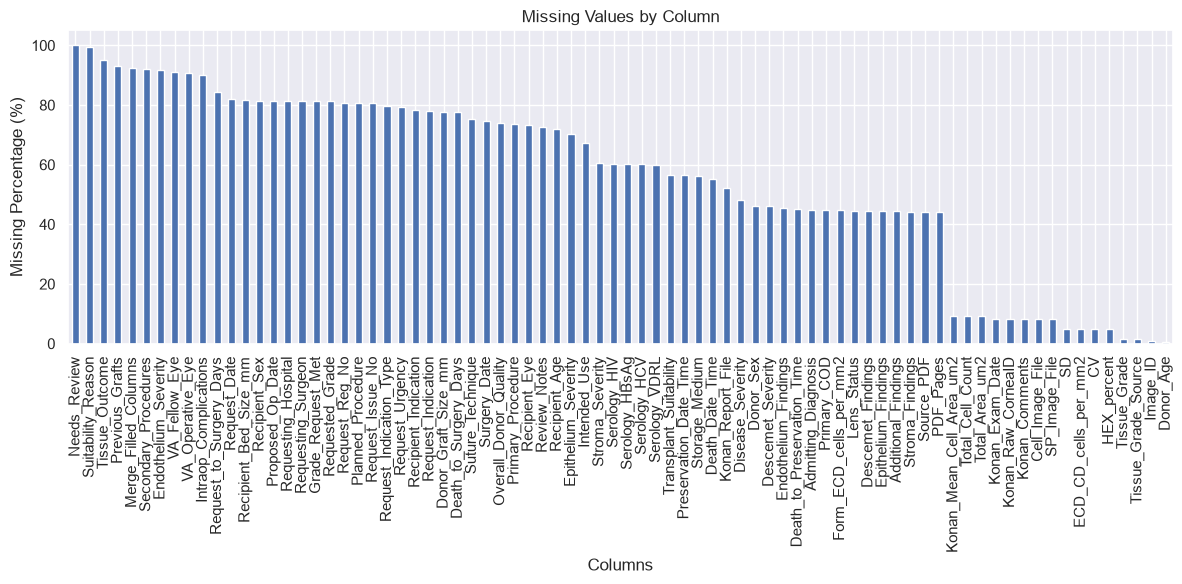

In [10]:
missing_data = missing_report[
    missing_report["Missing_Count"] > 0
]

plt.figure(figsize=(12, 6))

missing_data["Missing_Percentage"].plot(kind="bar")

plt.title("Missing Values by Column")
plt.xlabel("Columns")
plt.ylabel("Missing Percentage (%)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [11]:
important_columns = [
    "Image_ID",
    "SP_Image_File",
    "Disease_Label"
]

available_columns = [
    col for col in important_columns
    if col in df.columns
]

display(df[df[available_columns].isna().any(axis=1)][available_columns].head(30))

,Image_ID,SP_Image_File,Disease_Label
29,NEB-2020-09-12683 R_SP,NaN,Normal
48,NEB-2020-09-12702 R_SP,NaN,Folds
49,NEB-2020-09-12703 L_SP,NaN,Folds
50,NEB-2020-09-12704 L_SP,NaN,Normal
51,NEB-2020-09-12705 R_SP,NaN,Normal
52,NEB-2020-10-12706 R_SP,NaN,Folds
53,NEB-2020-10-12707 L_SP,NaN,Normal
54,NEB-2020-10-12708 L_SP,NaN,FECD; Polymorphism and pleomorphism; Low cell density
55,NEB-2020-10-12709 R_SP,NaN,FECD; Polymorphism and pleomorphism; Low cell density
56,NEB-2020-10-12710 L_SP,NaN,Guttata; Folds


In [12]:
duplicate_count = df.duplicated().sum()

print("Completely duplicated rows:", duplicate_count)

Completely duplicated rows: 0


In [13]:
if "SP_Image_File" in df.columns:

    sp_names = df["SP_Image_File"].dropna().astype(str).str.strip()

    print("Non-missing SP filenames:", len(sp_names))
    print("Unique SP filenames:", sp_names.nunique())
    print("Repeated SP filenames:", sp_names.duplicated().sum())

    repeated_names = sp_names[
        sp_names.duplicated(keep=False)
    ].unique()

    display(
        df[df["SP_Image_File"].isin(repeated_names)]
    )

Non-missing SP filenames: 967
Unique SP filenames: 967
Repeated SP filenames: 0


,Tissue_ID,Eye,Image_ID,Disease_Label,Disease_Severity,ECD_CD_cells_per_mm2,CV,HEX_percent,SD,Total_Cell_Count,Total_Area_um2,Epithelium_Findings,Epithelium_Severity,Stroma_Findings,Stroma_Severity,Descemet_Findings,Descemet_Severity,Endothelium_Findings,Endothelium_Severity,Additional_Findings,Tissue_Grade,Overall_Donor_Quality,Transplant_Suitability,Suitability_Reason,Primary_COD,Donor_Age,Tissue_Serial,Linkage_Status,Source_PDF,PDF_Pages,Konan_Report_File,SP_Image_File,Cell_Image_File,Konan_Raw_CorneaID,Konan_Exam_Date,Konan_Mean_Cell_Area_um2,Konan_Comments,Donor_Sex,Admitting_Diagnosis,Death_Date_Time,Preservation_Date_Time,Death_to_Preservation_Time,Storage_Medium,Serology_HBsAg,Serology_HCV,Serology_HIV,Serology_VDRL,Lens_Status,Form_ECD_cells_per_mm2,Intended_Use,Tissue_Outcome,Recipient_Age,Recipient_Eye,Recipient_Indication,Request_Indication,Previous_Grafts,Primary_Procedure,Secondary_Procedures,Surgery_Date,Donor_Graft_Size_mm,Recipient_Bed_Size_mm,Suture_Technique,Intraop_Complications,Death_to_Surgery_Days,Request_Reg_No,Request_Issue_No,Request_Date,Proposed_Op_Date,Request_Urgency,Request_Indication_Type,Recipient_Sex,VA_Operative_Eye,VA_Fellow_Eye,Requested_Grade,Planned_Procedure,Requesting_Surgeon,Requesting_Hospital,Request_to_Surgery_Days,Grade_Request_Met,Dataset_Part,Tissue_Grade_Source,Disease_Label_Source,Needs_Review,Review_Notes,Merge_Filled_Columns


In [14]:
for col in ["Image_ID", "Tissue_ID", "Eye"]:
    if col in df.columns:
        print(
            f"{col}:",
            df[col].nunique(dropna=True),
            "unique values out of",
            df[col].notna().sum(),
            "non-missing records"
        )

Image_ID: 1045 unique values out of 1045 non-missing records
Tissue_ID: 1054 unique values out of 1054 non-missing records
Eye: 2 unique values out of 1054 non-missing records


In [15]:
text_columns = df.select_dtypes(
    include=["object", "string"]
).columns.tolist()

print("Number of text columns:", len(text_columns))
print(text_columns)

Number of text columns: 72
['Tissue_ID', 'Eye', 'Image_ID', 'Disease_Label', 'Disease_Severity', 'Epithelium_Findings', 'Epithelium_Severity', 'Stroma_Findings', 'Stroma_Severity', 'Descemet_Findings', 'Descemet_Severity', 'Endothelium_Findings', 'Endothelium_Severity', 'Additional_Findings', 'Tissue_Grade', 'Overall_Donor_Quality', 'Transplant_Suitability', 'Suitability_Reason', 'Primary_COD', 'Linkage_Status', 'Source_PDF', 'Konan_Report_File', 'SP_Image_File', 'Cell_Image_File', 'Konan_Raw_CorneaID', 'Konan_Exam_Date', 'Konan_Comments', 'Donor_Sex', 'Admitting_Diagnosis', 'Death_Date_Time', 'Preservation_Date_Time', 'Death_to_Preservation_Time', 'Storage_Medium', 'Serology_HBsAg', 'Serology_HCV', 'Serology_HIV', 'Serology_VDRL', 'Lens_Status', 'Form_ECD_cells_per_mm2', 'Intended_Use', 'Tissue_Outcome', 'Recipient_Age', 'Recipient_Eye', 'Recipient_Indication', 'Request_Indication', 'Previous_Grafts', 'Primary_Procedure', 'Secondary_Procedures', 'Surgery_Date', 'Donor_Graft_Size_mm', 

In [16]:
for col in text_columns:
    df[col] = df[col].map(
        lambda x: (
            re.sub(r"\s+", " ", x).strip()
            if isinstance(x, str)
            else x
        )
    )

In [17]:
for col in text_columns:
    blank_count = (
        df[col].map(
            lambda x: isinstance(x, str) and x == ""
        )
    ).sum()

    if blank_count > 0:
        print(col, "blank strings:", blank_count)

In [18]:
for col in text_columns:
    df[col] = df[col].replace("", np.nan)

In [19]:
if "Disease_Label" in df.columns:

    print("Unique label combinations:",
          df["Disease_Label"].nunique(dropna=True))

    display(
        df["Disease_Label"]
        .value_counts(dropna=False)
        .to_frame("Count")
    )

Unique label combinations: 21


,Count
Disease_Label,
Normal,504
Folds,324
FECD; Polymorphism and pleomorphism; Low cell density,88
Guttata,53
Guttata; Folds,28
FECD; Polymorphism and pleomorphism; Low cell density; Folds,20
FECD; Polymorphism and pleomorphism; Low cell density; Guttata,8
Polymorphism and pleomorphism,5
Poor cornea,5


In [20]:
if "Disease_Label" in df.columns:

    df["Disease_Label"] = df["Disease_Label"].map(
        lambda x: (
            re.sub(r"\s*;\s*", "; ", x.strip())
            if isinstance(x, str)
            else x
        )
    )

In [21]:
if "Disease_Label" in df.columns:

    all_labels = set()

    for value in df["Disease_Label"].dropna():
        labels = [
            label.strip()
            for label in str(value).split(";")
            if label.strip()
        ]

        all_labels.update(labels)

    print("Individual label names:")

    for label in sorted(all_labels):
        print(label)

Individual label names:
FECD
Folds
Guttata
Low cell density
Normal
Not labelled (no CellChek report)
Polymorphism and pleomorphism
Poor cornea


In [22]:
image_folder = r"C:\Users\minsa_\OneDrive\Desktop\Disease_Cell_Images"

print("Folder exists:", os.path.isdir(image_folder))

Folder exists: True


In [23]:
from pathlib import Path

if "SP_Image_File" in df.columns:

    existing_files = {
        p.name.lower(): p
        for p in Path(image_folder).iterdir()
        if p.is_file()
    }

    def find_image(filename):
        if pd.isna(filename):
            return None

        name = str(filename).strip()
        return existing_files.get(name.lower())

    df["SP_Image_Path"] = df["SP_Image_File"].map(find_image)

    df["SP_Image_Exists"] = df["SP_Image_Path"].notna()

    print("Total dataset rows:", len(df))
    print("Images found:", df["SP_Image_Exists"].sum())
    print("Images not found:", (~df["SP_Image_Exists"]).sum())

    display(
        df.loc[
            ~df["SP_Image_Exists"],
            ["SP_Image_File"]
        ].head(30)
    )

Total dataset rows: 1054
Images found: 963
Images not found: 91


,SP_Image_File
29,NaN
34,NEB-2020-09-12688 L_SP.jpg
48,NaN
49,NaN
50,NaN
51,NaN
52,NaN
53,NaN
54,NaN
55,NaN


In [25]:
from PIL import Image

def is_readable_image(path):
    if path is None or pd.isna(path):
        return False

    try:
        with Image.open(path) as img:
            img.verify()
        return True
    except Exception:
        return False

if "SP_Image_Path" in df.columns:

    df["SP_Image_Readable"] = df["SP_Image_Path"].map(
        is_readable_image
    )

    print("Readable images:", df["SP_Image_Readable"].sum())
    print("Unreadable or missing images:",
          (~df["SP_Image_Readable"]).sum())

Readable images: 963
Unreadable or missing images: 91


In [26]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

display(df[numeric_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
ECD_CD_cells_per_mm2,1003.0,2591.799601,475.412965,0.0,2342.0,2591.0,2874.00,4484.0
CV,1003.0,38.014955,5.504016,0.0,35.0,38.0,41.00,74.0
HEX_percent,1003.0,53.750748,7.292826,0.0,50.0,54.0,58.00,76.0
SD,1002.0,152.120758,48.581254,0.0,127.0,144.0,164.00,753.0
Total_Cell_Count,956.0,106.571130,17.720523,0.0,104.0,108.0,113.00,204.0
Total_Area_um2,956.0,42088.297071,9503.987603,0.0,37487.5,41439.5,46317.75,100692.0
Donor_Age,1050.0,59.672381,10.901732,15.0,54.0,62.0,68.00,78.0
Tissue_Serial,1054.0,15356.775142,1460.294459,12654.0,14740.5,15286.5,16259.75,17650.0
PDF_Pages,590.0,4.235593,1.937150,1.0,3.0,4.0,5.00,17.0
Konan_Mean_Cell_Area_um2,956.0,398.596234,99.833433,0.0,350.0,386.0,427.25,1479.0


In [27]:
biomarker_columns = [
    "ECD_CD_cells_per_mm2",
    "CV",
    "HEX_percent"
]

for col in biomarker_columns:
    if col in df.columns:
        numeric_values = pd.to_numeric(
            df[col], errors="coerce"
        )

        negative_count = (numeric_values < 0).sum()

        print(f"{col}: negative values = {negative_count}")

ECD_CD_cells_per_mm2: negative values = 0
CV: negative values = 0
HEX_percent: negative values = 0


In [28]:
for col in biomarker_columns:
    if col in df.columns:

        values = pd.to_numeric(
            df[col], errors="coerce"
        ).dropna()

        if len(values) == 0:
            continue

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        outliers = df[
            pd.to_numeric(df[col], errors="coerce").lt(lower)
            | pd.to_numeric(df[col], errors="coerce").gt(upper)
        ]

        print(
            f"{col}: {len(outliers)} potential outlier records"
        )

ECD_CD_cells_per_mm2: 34 potential outlier records
CV: 21 potential outlier records
HEX_percent: 19 potential outlier records


In [29]:
categorical_candidates = [
    "Disease_Label",
    "Disease_Severity",
    "Endothelium_Findings",
    "Endothelium_Severity",
    "Eye"
]

for col in categorical_candidates:
    if col in df.columns:
        print(f"\n--- {col} ---")
        display(
            df[col].value_counts(dropna=False).to_frame("Count")
        )


--- Disease_Label ---


,Count
Disease_Label,
Normal,504
Folds,324
FECD; Polymorphism and pleomorphism; Low cell density,88
Guttata,53
Guttata; Folds,28
FECD; Polymorphism and pleomorphism; Low cell density; Folds,20
FECD; Polymorphism and pleomorphism; Low cell density; Guttata,8
Polymorphism and pleomorphism,5
Poor cornea,5



--- Disease_Severity ---


,Count
Disease_Severity,
NaN,509
Mild,475
Moderate,56
Severe,14



--- Endothelium_Findings ---


,Count
Endothelium_Findings,
NaN,479
Stress lines; central; few,96
Stress lines; central; few (release form: few stress lines),78
Relative number of stress lines: few (release form: few stress lines),61
Relative number of stress lines: few,52
...,...
Stress lines; few; cell drop-out mild (release form: few stress lines),1
Stress lines; central/peripheral marked; few; cell drop-out mild; debris mild,1
Stress lines; central and peripheral; few; cell drop-out mild; RBCs mild (release form: few stress lines),1



--- Endothelium_Severity ---


,Count
Endothelium_Severity,
NaN,967
Mild,62
Mild (cell drop-out),18
Moderate,2
Mild (as read),1
Mild (RBCs on endo),1
Moderate (RBCs on endo),1
"Mild (cell drop-out, debris)",1
"Mild (cell drop-out, RBCs)",1



--- Eye ---


,Count
Eye,
Right,757
Left,297


In [30]:
output_folder = "ACITES_Cleaning_Outputs"

os.makedirs(output_folder, exist_ok=True)

# Save the cleaned working dataset
df.to_excel(
    os.path.join(
        output_folder,
        "Combined_Dataset_Cleaning_Working.xlsx"
    ),
    index=False
)

# Save the missing-value report
missing_report.to_csv(
    os.path.join(
        output_folder,
        "missing_value_report.csv"
    )
    ,
    index=True
)

print("Cleaning outputs saved.")

Cleaning outputs saved.
